# 演習8：joint-state準備の直接圧縮とhardware-awareな誤り抑制

06・07で見えなかった干渉信号に対し、**joint-state準備の直接圧縮**と、
**較正を使う配置・最適化・Pauli twirling・dynamical decoupling (DD)** を実装します。
FakeKawasakiと実機の両方で、同じ3条件を比較します。06・07を先に実行する必要はありません。

| arm        | 準備                   | 配置・コンパイル                     | 追加抑制                    |
| ---------- | ---------------------- | ------------------------------------ | --------------------------- |
| paired     | 06の分岐制御による準備 | optimization_level=1                 | なし                        |
| joint      | joint-stateを直接圧縮  | pairedと同じ初期配置、level=1        | なし                        |
| suppressed | jointと同じ準備        | 較正に基づく9-qubit経路選択、level=3 | 明示的Pauli twirling＋XX-DD |

`paired → joint` は準備方式の比較、`joint → suppressed` は配置・最適化・抑制をまとめた比較です。
後者だけから、DDやtwirlingそれぞれの寄与は分離できません。

**これはFireOpalの再実装ではありません。** オープンなQiskitで実行できる改善を検証します。
FireOpalのパルス最適化・測定誤り緩和等は含めず、論文の性能再現や実機での信号回復は保証しません。
Gaussian更新・ギャップ推定は行いません。実機接続と送信は既定で無効です。


In [1]:
# 初回は必要に応じて有効にし、インストール後にカーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "qiskit-ibm-runtime>=0.43,<0.44" "qiskit-aer>=0.17,<0.18"


## 1．固定データと補助関数

06・07と同じ固定コミットから、同じH₄・準備M6・発展M16を読み込みます。
下の初期化セルで `H4_CACHE_DIR` と `H4_OFFLINE` を指定できます。SHA-256を確認して既存データを再利用します。
新しいjoint-stateの準備回路は、このNotebook内で実際に最適化します。


In [2]:
H4_DATA_COMMIT = "4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43"
# 保存先を指定する場合の例（Google Driveは先にmountする）:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
H4_CACHE_DIR = (
    None  # None: H4_DATA_DIR環境変数 → 取得済みリポジトリ → ユーザーキャッシュ
)
H4_OFFLINE = False  # True: ダウンロードせず、既存ファイルのみを使用

import os, json, hashlib, base64, tempfile
from pathlib import Path
from urllib.request import urlopen

SNAPSHOT_DIGEST = "6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3"
ASSET_DIGEST = SNAPSHOT_DIGEST
_H4_URL = f"https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{H4_DATA_COMMIT}/hands_on/exercises/"
_H4_RUNTIME = {
    "h4_measurement.py": "d4dea4170f5e925599dcbbbc3b2c0ee7f2da1e25d7844ec024759e415c3a35f4",
    "h4_snapshot.py": "163691a0c005c844e0e449411c59eb5192218402df999c77056cbd7b223be997",
}


def snapshot_root():
    explicit = os.environ.get("H4_DATA_DIR") or H4_CACHE_DIR
    root = Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(), *Path.cwd().parents]:
            for candidate in [
                parent / "data/h4_pec_v1",
                parent / "hands_on/exercises/data/h4_pec_v1",
            ]:
                if (candidate / "manifest.json").is_file():
                    root = candidate
                    break
            if root is not None:
                break
    if root is None:
        root = Path.home() / ".cache/ftqc_handson/h4_pec_v1"
    if (
        str(root).startswith("/content/drive/MyDrive/")
        and not Path("/content/drive/MyDrive").is_dir()
    ):
        raise FileNotFoundError(
            '先に drive.mount("/content/drive") でGoogle Driveを接続してください'
        )
    manifest = root / "manifest.json"
    if (
        manifest.is_file()
        and hashlib.sha256(manifest.read_bytes()).hexdigest() != SNAPSHOT_DIGEST
    ):
        raise ValueError("Snapshot manifest differs from the pinned h4-pec-v1 manifest")
    return root


def _h4_fetch(path, url, digest):
    path = Path(path)
    if path.is_file():
        raw = path.read_bytes()
    else:
        if H4_OFFLINE:
            raise FileNotFoundError(
                f"Offline: missing {path}; pre-download the required data"
            )
        try:
            with urlopen(url, timeout=60) as response:
                raw = response.read()
        except Exception as exc:
            raise RuntimeError(
                f"H4データを取得できません: {path.name}. 接続またはH4_DATA_DIR/H4_CACHE_DIRを確認してください。"
            ) from exc
        if hashlib.sha256(raw).hexdigest() != digest:
            raise ValueError(f"Snapshot checksum mismatch: {path.name}")
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent, delete=False) as stream:
                tmp = Path(stream.name)
                stream.write(raw)
            os.replace(tmp, path)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest() != digest:
        raise ValueError(f"Snapshot checksum mismatch: {path.name}")
    return raw


def _h4_data(relative):
    digest = (
        SNAPSHOT_DIGEST
        if relative == "manifest.json"
        else SNAPSHOT_INDEX["files"][relative]
    )
    return _h4_fetch(
        snapshot_root() / relative, _H4_URL + "data/h4_pec_v1/" + relative, digest
    )


SNAPSHOT_INDEX = json.loads(_h4_data("manifest.json"))


class _H4Assets:
    """Read only the requested asset; no notebook-embedded binary strings."""

    def __init__(self, row):
        self.row = row

    def __getitem__(self, key):
        raw = _h4_data(self.row["id"] + "/" + self.row["assets"][key])
        return base64.b64encode(raw).decode()


def _h4_geometry(geometry):
    row = next((r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None)
    if row is None:
        raise ValueError("Unknown GEOMETRY; choose an ID from list_geometries()")
    cat = json.loads(_h4_data(geometry + "/catalog.json"))
    for name in ["preparation", "evolution"]:
        cat[name] = {int(k) if k != "exact" else k: v for k, v in cat[name].items()}
    return _H4Assets(row), cat, json.loads(_h4_data(geometry + "/provenance.json"))


ASSETS, CIRCUIT_CATALOG, PROVENANCE = _h4_geometry("R_2p00000000")
exec(
    compile(_h4_data("exact_preparation.py"), "h4_pec_v1/exact_preparation.py", "exec"),
    globals(),
)
_h4_cache_root = snapshot_root
for _name, _digest in _H4_RUNTIME.items():
    _local = snapshot_root().parent.parent / "tools" / _name
    _path = (
        _local
        if _local.is_file()
        else snapshot_root().parent
        / (snapshot_root().name + "_runtime")
        / H4_DATA_COMMIT
        / _name
    )
    exec(
        compile(_h4_fetch(_path, _H4_URL + "tools/" + _name, _digest), _name, "exec"),
        globals(),
    )
# The pinned runtime supplies measurement/inference helpers. Replace its eager
# snapshot reader with the verified, per-file cache above.
snapshot_geometry = _h4_geometry
snapshot_root = _h4_cache_root


def download_h4_data(
    geometries="all", prep_m=(4, 6, 8, "exact"), evolution_m=(8, 16, 32, "exact")
):
    """Optional prefetch for offline use. This never changes active circuits."""
    ids = (
        [r["id"] for r in SNAPSHOT_INDEX["geometries"]]
        if geometries == "all"
        else list(geometries)
    )
    count = 0
    for geometry in ids:
        row = next(
            (r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None
        )
        if row is None:
            raise ValueError("Unknown GEOMETRY")
        assets, cat, _ = _h4_geometry(geometry)
        keys = {"model"}
        for m in prep_m:
            keys.update(cat["preparation"][m]["keys"].values())
        for m in evolution_m:
            keys.add(cat["evolution"][m]["key"])
        for key in sorted(keys):
            assets[key]
            count += 1
    print(f"Cached {len(ids)} geometries / {count} assets in {snapshot_root()}")


print(
    "H4 data cache:",
    snapshot_root(),
    "— missing files are downloaded on demand; existing files are verified and reused.",
)


R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
H4 data cache: /Users/payashi/Documents/research/IBM_handson/hands_on/exercises/data/h4_pec_v1 — missing files are downloaded on demand; existing files are verified and reused.


In [ ]:
"""Exercise 08 helpers, embedded verbatim in the notebook for standalone Colab use.

The pinned H4 bootstrap supplies np, QuantumCircuit, Statevector, qpy, transpile,
A_APPROX, U_APPROX, EVOLUTION_APPROX and the selected model. No account access
or job submission occurs on loading this file.
"""
import hashlib
import json
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
from qiskit import QuantumCircuit, qpy, transpile
from qiskit.circuit import Parameter, Delay
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector, Operator, Pauli
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import (
    ALAPScheduleAnalysis,
    ConstrainedReschedule,
    PadDelay,
    PadDynamicalDecoupling,
)

CHAIN = (8, 0, 1, 2, 3, 4, 5, 6, 7)
ARMS = ("paired", "joint", "suppressed")


def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def joint_mps(target, chi=16):
    """TT-SVD of the nine-qubit joint state in ancilla-first chain order."""
    target = np.asarray(target, complex)
    if target.shape != (512,) or not np.isclose(np.linalg.norm(target), 1):
        raise ValueError("A normalized nine-qubit joint target is required")
    if not isinstance(chi, int) or isinstance(chi, bool) or chi < 1:
        raise ValueError("chi must be a positive integer")
    axes = [8 - q for q in CHAIN]
    tensor = target.reshape([2] * 9).transpose(axes)
    cores, rank = [], 1
    for _ in range(8):
        u, s, vh = np.linalg.svd(tensor.reshape(rank * 2, -1), full_matrices=False)
        keep = min(chi, len(s))
        cores.append(u[:, :keep].reshape(rank, 2, keep))
        tensor = s[:keep, None] * vh[:keep]
        rank = keep
    cores.append(tensor.reshape(rank, 2, 1))
    rebuilt = cores[0][0]
    for core in cores[1:]:
        rebuilt = np.tensordot(rebuilt, core, axes=(-1, 0))
    state = rebuilt[..., 0].transpose(np.argsort(axes)).reshape(-1)
    retained = float(np.linalg.norm(state) ** 2)
    state /= np.sqrt(retained)
    return cores, state, retained


def two_site_view(state, pair):
    # Qiskit's two-qubit matrix basis is |q_second q_first>.
    a, b = pair
    axes = [8 - b, 8 - a] + [i for i in range(9) if i not in (8 - b, 8 - a)]
    return state.reshape([2] * 9).transpose(axes).reshape(4, -1), axes


def apply_two(state, gate, pair):
    matrix, axes = two_site_view(state, pair)
    return (gate @ matrix).reshape([2] * 9).transpose(np.argsort(axes)).reshape(-1)


def initial_joint_state():
    # A product determinant times |+>_ancilla, prepared without controlled gates.
    state = np.zeros(512, complex)
    state[165] = state[165 + 256] = 1 / np.sqrt(2)
    return state


def compress_joint(target, layers=8, sweeps=2000, seeds=(3, 17, 42), chi=16):
    if layers < 1 or sweeps < 1 or not seeds:
        raise ValueError("Positive layers/sweeps and at least one seed are required")
    cores, mps_target, retained = joint_mps(target, chi)
    pairs = [
        (CHAIN[j], CHAIN[j + 1])
        for layer in range(layers)
        for j in range(layer % 2, 8, 2)
    ]
    best, runs = None, []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        gates = []
        for _ in pairs:
            z = np.eye(4) + 0.05 * (
                rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4))
            )
            u, _, vh = np.linalg.svd(z)
            gates.append(u @ vh)
        history = []
        for sweep in range(sweeps):
            if sweep % 2 == 0:
                suffix = [None] * (len(gates) + 1)
                suffix[-1] = mps_target
                for j in reversed(range(len(gates))):
                    suffix[j] = apply_two(suffix[j + 1], gates[j].conj().T, pairs[j])
                state = initial_joint_state()
                for j, pair in enumerate(pairs):
                    x, _ = two_site_view(state, pair)
                    y, _ = two_site_view(suffix[j + 1], pair)
                    u, _, vh = np.linalg.svd(y @ x.conj().T)
                    gates[j] = u @ vh
                    state = apply_two(state, gates[j], pair)
            else:
                prefix = [initial_joint_state()]
                for gate, pair in zip(gates, pairs):
                    prefix.append(apply_two(prefix[-1], gate, pair))
                state = mps_target.copy()
                for j in reversed(range(len(gates))):
                    x, _ = two_site_view(prefix[j], pairs[j])
                    y, _ = two_site_view(state, pairs[j])
                    u, _, vh = np.linalg.svd(y @ x.conj().T)
                    gates[j] = u @ vh
                    state = apply_two(state, gates[j].conj().T, pairs[j])
            prepared = initial_joint_state()
            for gate, pair in zip(gates, pairs):
                prepared = apply_two(prepared, gate, pair)
            history.append(float(abs(np.vdot(mps_target, prepared)) ** 2))
        fidelity = float(abs(np.vdot(target, prepared)) ** 2)
        runs.append(dict(seed=seed, fidelity=fidelity, history=history))
        print(f"Joint compression: seed={seed}, fidelity={fidelity:.8f}", flush=True)
        if best is None or fidelity > best["fidelity"]:
            best = dict(fidelity=fidelity, gates=np.array(gates), seed=seed)
    circuit = QuantumCircuit(9, name="joint_MPS_compressed")
    for q in (0, 2, 5, 7):
        circuit.x(q)
    circuit.h(8)
    for gate, pair in zip(best["gates"], pairs):
        circuit.unitary(gate, list(pair))
    actual = Statevector.from_instruction(circuit).data
    np.testing.assert_allclose(
        abs(np.vdot(target, actual)) ** 2, best["fidelity"], atol=1e-11
    )
    fingerprint = hashlib.sha256(
        best["gates"].tobytes() + np.array(pairs).tobytes()
    ).hexdigest()
    report = dict(
        layers=layers,
        sweeps=sweeps,
        seeds=list(seeds),
        selected_seed=best["seed"],
        chi=chi,
        bond_dimensions=[c.shape[2] for c in cores[:-1]],
        mps_retained_norm_squared=retained,
        fidelity=best["fidelity"],
        circuit_digest=fingerprint,
        two_qubit_blocks=len(pairs),
        runs=runs,
    )
    return circuit, report


def logical_phase_circuit(prep, length):
    beta = Parameter("beta")
    circuit = QuantumCircuit(9)
    circuit.compose(prep, inplace=True)
    for _ in range(length):
        circuit.compose(EVOLUTION_APPROX, range(8), inplace=True)
    circuit.p(beta, 8)
    circuit.compose(prep.inverse(), inplace=True)
    circuit.measure_all()
    return circuit


def ideal_signal(prep, length, beta):
    phi = Statevector.from_instruction(prep).data
    evolution = np.linalg.matrix_power(U_APPROX, length)
    a, b = [np.vdot(branch, evolution @ branch) for branch in [phi[:256], phi[256:]]]
    return np.clip(abs(a + np.exp(1j * np.asarray(beta)) * b) ** 2, 0, 1)


def instruction_cost(circuit, backend):
    """Calibration-based heuristic, not an estimated circuit success probability."""
    score, missing = 0.0, 0
    for item in circuit.data:
        if item.operation.name in ("barrier", "delay"):
            continue
        qubits = tuple(circuit.find_bit(q).index for q in item.qubits)
        entries = backend.target.get(item.operation.name, {})
        prop = entries.get(qubits)
        error = getattr(prop, "error", None)
        if error is None:
            error = 0.0 if item.operation.name == "rz" else 0.01
            missing += 1
        score -= np.log1p(-min(max(float(error), 0), 0.999999))
    return float(score), missing


def calibrated_paths(backend, count=4, beam_width=256):
    edges = {}
    neighbors = {q: set() for q in range(backend.num_qubits)}
    for name in backend.target.operation_names:
        operation = backend.target.operation_from_name(name)
        if operation.num_qubits != 2:
            continue
        for pair, prop in backend.target[name].items():
            if pair is None:
                continue
            a, b = pair
            error = 0.01 if prop is None or prop.error is None else prop.error
            key = tuple(sorted(pair))
            edges[key] = min(edges.get(key, 1.0), -np.log1p(-min(error, 0.999999)))
            neighbors[a].add(b)
            neighbors[b].add(a)
    readout = {}
    for q in neighbors:
        prop = backend.target.get("measure", {}).get((q,))
        error = 0.01 if prop is None or prop.error is None else prop.error
        readout[q] = -np.log1p(-min(error, 0.999999))
    beam = [(readout[q], (q,)) for q in neighbors if neighbors[q]]
    for _ in range(8):
        expanded = [
            (cost + edges[tuple(sorted((path[-1], q)))] + readout[q], path + (q,))
            for cost, path in beam
            for q in sorted(neighbors[path[-1]])
            if q not in path
        ]
        beam = sorted(expanded)[:beam_width]
        if not beam:
            raise ValueError("No nine-qubit path found in this target")
    paths, seen = [], set()
    for _, path in beam:
        canonical = min(path, path[::-1])
        if canonical not in seen:
            paths.append(path)
            seen.add(canonical)
        if len(paths) >= count:
            break
    return paths


def chain_layout(path):
    layout = [None] * 9
    for logical, physical in zip(CHAIN, path):
        layout[logical] = physical
    return layout


def active_qubits(circuit):
    return sorted(
        {
            circuit.find_bit(q).index
            for item in circuit.data
            if item.operation.name not in ("barrier", "delay")
            for q in item.qubits
        }
    )


def twirl_native(circuit, seed):
    """Explicit exact Pauli twirls for native CX/CZ/ECR, including global phases."""
    rng = np.random.default_rng(seed)
    labels = [a + b for a in "IXYZ" for b in "IXYZ"]
    paulis = [Pauli(label).to_matrix() for label in labels]
    cache = {}
    out = circuit.copy_empty_like()
    out.global_phase = circuit.global_phase

    def append_pauli(label, qubits):
        for letter, q in zip(label[::-1], qubits):
            if letter != "I":
                getattr(out, letter.lower())(q)

    for item in circuit.data:
        op = item.operation
        if op.num_qubits != 2 or op.name == "barrier":
            out.append(op, item.qubits, item.clbits)
            continue
        if op.name not in ("cx", "cz", "ecr"):
            raise ValueError(
                f"Explicit Pauli twirling supports CX/CZ/ECR, received {op.name}"
            )
        if op.name not in cache:
            u = Operator(op).data
            table = []
            for pre in paulis:
                conjugated = u @ pre @ u.conj().T
                overlaps = np.array(
                    [np.trace(p.conj().T @ conjugated) / 4 for p in paulis]
                )
                index = int(np.argmax(abs(overlaps)))
                if not np.isclose(abs(overlaps[index]), 1.0, atol=1e-10):
                    raise ValueError("Native gate is not Clifford")
                table.append((labels[index], float(np.angle(overlaps[index]))))
            cache[op.name] = table
        index = int(rng.integers(16))
        post, phase = cache[op.name][index]
        append_pauli(labels[index], item.qubits)
        out.append(op, item.qubits, item.clbits)
        append_pauli(post, item.qubits)
        out.global_phase += phase
    return out


def schedule_native(circuit, backend, dd=False):
    active = active_qubits(circuit)
    target = backend.target
    unbarred = circuit.copy_empty_like()
    unbarred.global_phase = circuit.global_phase
    for item in circuit.data:
        if item.operation.name != "barrier":
            unbarred.append(item.operation, item.qubits, item.clbits)
    padding = (
        PadDynamicalDecoupling(
            target=target,
            dd_sequence=[XGate(), XGate()],
            qubits=active,
            pulse_alignment=target.pulse_alignment,
            skip_reset_qubits=False,
        )
        if dd
        else PadDelay(target=target)
    )
    scheduled = PassManager(
        [
            ALAPScheduleAnalysis(target=target),
            ConstrainedReschedule(target=target),
            padding,
        ]
    ).run(unbarred)
    # Padding unused device wires would make a local density simulation enormous.
    # They never interact with the active circuit and are excluded in both modes.
    clean = scheduled.copy_empty_like()
    clean.global_phase = scheduled.global_phase
    for item in scheduled.data:
        if (
            item.operation.name == "delay"
            and scheduled.find_bit(item.qubits[0]).index not in active
        ):
            continue
        clean.append(item.operation, item.qubits, item.clbits)
    return clean


def circuit_signature(circuit):
    return digest_json(
        dict(
            qubits=circuit.num_qubits,
            clbits=circuit.num_clbits,
            phase=str(circuit.global_phase),
            instructions=[
                [
                    i.operation.name,
                    [str(p) for p in i.operation.params],
                    getattr(i.operation, "unit", None),
                    [circuit.find_bit(q).index for q in i.qubits],
                    [circuit.find_bit(c).index for c in i.clbits],
                ]
                for i in circuit.data
            ],
        )
    )


def compact_unitary_circuit(circuit):
    active = active_qubits(circuit)
    mapping = {q: j for j, q in enumerate(active)}
    compact = QuantumCircuit(len(active))
    compact.global_phase = circuit.global_phase
    for item in circuit.data:
        if item.operation.name not in ("measure", "barrier", "delay"):
            compact.append(
                item.operation,
                [mapping[circuit.find_bit(q).index] for q in item.qubits],
            )
    return compact


def compile_comparison(backend, joint, compression, config):
    if compression["fidelity"] < config["minimum_joint_fidelity"]:
        raise ValueError(
            "Joint compression fidelity is below the configured submission threshold"
        )
    paired = transpile(
        logical_phase_circuit(A_APPROX, config["L"]),
        backend=backend,
        optimization_level=1,
        seed_transpiler=7,
        num_processes=1,
    )
    standard_layout = paired.layout.initial_index_layout(filter_ancillas=True)
    simple_joint = transpile(
        logical_phase_circuit(joint, config["L"]),
        backend=backend,
        initial_layout=standard_layout,
        optimization_level=1,
        seed_transpiler=7,
        approximation_degree=1.0,
        num_processes=1,
    )
    candidates = []
    for path in calibrated_paths(backend, count=config["layout_candidates"]):
        compiled = transpile(
            logical_phase_circuit(joint, config["L"]),
            backend=backend,
            initial_layout=chain_layout(path),
            optimization_level=3,
            seed_transpiler=7,
            approximation_degree=1.0,
            num_processes=1,
        )
        cost, missing = instruction_cost(compiled, backend)
        candidates.append((cost, missing, compiled))
    cost, missing, aware = min(candidates, key=lambda item: item[0])
    templates = dict(paired=paired, joint=simple_joint, suppressed=aware)
    ideals = {
        arm: ideal_signal(
            A_APPROX if arm == "paired" else joint, config["L"], config["phases"]
        )
        for arm in ARMS
    }
    circuits, schedule, reports = [], [], []
    per_circuit = config["shots_per_phase"] // config["randomizations"]
    for arm in ARMS:
        ideal_errors = []
        for repeat in range(config["randomizations"]):
            for j, beta in enumerate(config["phases"]):
                template = templates[arm]
                bound = template.assign_parameters(
                    {next(iter(template.parameters)): beta}
                )
                if arm == "suppressed":
                    # Reuse each random Pauli pattern across the entire phase scan.
                    bound = twirl_native(bound, config["seed"] + 1000 * repeat)
                    # Lower Pauli gates into the native basis without moving physical wires.
                    bound = transpile(
                        bound,
                        backend=backend,
                        optimization_level=0,
                        initial_layout=list(range(backend.num_qubits)),
                        routing_method="none",
                        seed_transpiler=7,
                        num_processes=1,
                    )
                scheduled = schedule_native(bound, backend, dd=(arm == "suppressed"))
                if len(active_qubits(scheduled)) > config["max_active_qubits"]:
                    raise ValueError(
                        "Routing uses too many qubits for the configured local simulation limit"
                    )
                # Check every actual native circuit before it becomes eligible for submission.
                actual = (
                    abs(
                        Statevector.from_instruction(
                            compact_unitary_circuit(scheduled)
                        ).data[0]
                    )
                    ** 2
                )
                expected = float(ideals[arm][j])
                ideal_errors.append(float(abs(actual - expected)))
                if not np.isclose(actual, expected, atol=1e-7, rtol=0):
                    raise ValueError(
                        f"Ideal circuit check failed: {arm}, beta={beta}, "
                        f"actual={actual}, expected={expected}"
                    )
                circuits.append(scheduled)
                schedule.append(dict(arm=arm, repeat=repeat, phase_index=j, beta=beta))
        representative = circuits[-len(config["phases"]) * config["randomizations"]]
        score, missing = instruction_cost(representative, backend)
        report = dict(
            arm=arm,
            depth=representative.depth(),
            two_qubit_gates=sum(
                i.operation.num_qubits == 2 for i in representative.data
            ),
            x_gates=representative.count_ops().get("x", 0),
            delay_instructions=representative.count_ops().get("delay", 0),
            active_physical_qubits=active_qubits(representative),
            initial_layout=templates[arm].layout.initial_index_layout(
                filter_ancillas=True
            ),
            calibration_cost=score,
            missing_calibration_entries=missing,
        )
        report["ideal_probability_max_error"] = max(ideal_errors)
        reports.append(report)
        print(json.dumps(report), flush=True)
    order = np.random.default_rng(config["seed"]).permutation(len(circuits))
    circuits = [circuits[int(j)] for j in order]
    schedule = [schedule[int(j)] for j in order]
    properties = backend.properties()
    dense_phase = np.linspace(-np.pi, np.pi, 401)
    ideal_curves = {
        arm: ideal_signal(
            A_APPROX if arm == "paired" else joint, config["L"], dense_phase
        ).tolist()
        for arm in ARMS
    }
    used = sorted({q for report in reports for q in report["active_physical_qubits"]})
    qubit_calibration = [
        dict(
            qubit=q,
            t1=backend.target.qubit_properties[q].t1,
            t2=backend.target.qubit_properties[q].t2,
        )
        for q in used
    ]
    spec = dict(
        configuration=config,
        backend=backend.name,
        num_qubits=backend.num_qubits,
        calibration_last_update=properties.last_update_date.isoformat(),
        compression_digest=compression["circuit_digest"],
        compression_fidelity=compression["fidelity"],
        reports=reports,
        schedule=schedule,
        shots_per_circuit=per_circuit,
        ideal_phase_grid=dense_phase.tolist(),
        ideal_curves=ideal_curves,
        qubit_calibration=qubit_calibration,
        isa_signatures=[circuit_signature(c) for c in circuits],
    )
    key = digest_json(spec)
    print(
        f"Preview: {len(circuits)} circuits × {per_circuit} shots = {len(circuits) * per_circuit}"
    )
    return dict(specification=spec, circuits=circuits, key=key)


def run_fake_comparison(preview, backend):
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import RelaxationNoisePass

    simulator = AerSimulator.from_backend(
        backend,
        method="density_matrix",
        max_parallel_threads=4,
        max_parallel_experiments=1,
        enable_truncation=True,
    )
    if simulator.options.noise_model.is_ideal():
        raise ValueError("A nonideal fake backend noise model is required")
    props = backend.target.qubit_properties
    t1s = [p.t1 for p in props]
    t2s = [min(p.t2, 2 * p.t1) for p in props]
    idle_noise = PassManager(
        [RelaxationNoisePass(t1s=t1s, t2s=t2s, dt=backend.dt, op_types=[Delay])]
    )
    raw = []
    for j, circuit in enumerate(preview["circuits"]):
        noisy = idle_noise.run(circuit)
        result = simulator.run(
            noisy,
            shots=preview["specification"]["shots_per_circuit"],
            seed_simulator=preview["specification"]["configuration"]["seed"] + j,
        ).result()
        if not result.success:
            raise RuntimeError(result.status)
        raw.append(dict(result.get_counts()))
        if (j + 1) % 12 == 0:
            print(
                f"Local noisy simulation: {j + 1}/{len(preview['circuits'])}",
                flush=True,
            )
    return dict(
        source="fake_raw_counts",
        specification=preview["specification"],
        counts=raw,
        noise_description="Snapshot gate/readout noise plus T1/T2 relaxation on explicit delays; no added coherent drift",
    )


def atomic_json(path, record):
    import os
    import tempfile

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", dir=path.parent, delete=False) as stream:
        temp = Path(stream.name)
        json.dump(record, stream, indent=2)
    try:
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def acquire_real_comparison(preview, service, backend, instance, directory, config):
    if preview is None or service is None or backend is None:
        raise RuntimeError(
            "Connect and inspect the real-backend preview before submission"
        )
    spec = preview["specification"]
    if spec["configuration"] != config or spec["backend"] != backend.name:
        raise ValueError("Settings changed; regenerate the preview")
    spec = dict(spec, instance_sha256=hashlib.sha256(instance.encode()).hexdigest())
    key = digest_json(spec)
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / (key + ".json")
    if path.exists():
        record = json.loads(path.read_text())
        if record["specification"] != spec:
            raise ValueError("Stored specification differs")
        if "counts" in record:
            return record, path
        if "job_id" not in record:
            raise RuntimeError(
                f"Interrupted submission marker: {path}; inspect IBM jobs before recovery"
            )
        job = service.job(record["job_id"])
    else:
        from qiskit_ibm_runtime import SamplerV2

        qpy_path = path.with_suffix(".qpy")
        with qpy_path.open("wb") as stream:
            qpy.dump(preview["circuits"], stream)
        record = dict(
            source="ibm_submission",
            specification=spec,
            isa_qpy=qpy_path.name,
            created_at_utc=datetime.now(timezone.utc).isoformat(),
        )
        with path.open("x") as stream:
            json.dump(record, stream, indent=2)
        # Suppression is explicit in the submitted circuits. Avoid a second hidden layer.
        options = dict(
            dynamical_decoupling=dict(enable=False),
            twirling=dict(enable_gates=False, enable_measure=False),
        )
        job = SamplerV2(mode=backend, options=options).run(
            preview["circuits"], shots=spec["shots_per_circuit"]
        )
        record["job_id"] = job.job_id()
        atomic_json(path, record)
        print("Saved job ID:", record["job_id"], flush=True)
    record.update(
        source="ibm_raw_counts",
        counts=[dict(pub.data.meas.get_counts()) for pub in job.result()],
        retrieved_at_utc=datetime.now(timezone.utc).isoformat(),
    )
    atomic_json(path, record)
    return record, path


def aggregate_comparison(record):
    spec = record["specification"]
    config = spec["configuration"]
    schedule, raw = spec["schedule"], record["counts"]
    if len(raw) != len(schedule):
        raise ValueError("Incomplete counts")
    expected = {
        (arm, repeat, j)
        for arm in ARMS
        for repeat in range(config["randomizations"])
        for j in range(len(config["phases"]))
    }
    seen, totals = (
        set(),
        {
            arm: [
                np.zeros(len(config["phases"]), int),
                np.zeros(len(config["phases"]), int),
            ]
            for arm in ARMS
        },
    )
    for row, counts in zip(schedule, raw):
        key = (row["arm"], row["repeat"], row["phase_index"])
        if (
            key not in expected
            or key in seen
            or not np.isclose(row["beta"], config["phases"][key[2]], atol=1e-12)
        ):
            raise ValueError("Duplicate, missing, or mismatched PUB")
        seen.add(key)
        if not counts or any(
            not isinstance(s, str)
            or len(s) != 9
            or set(s) - set("01")
            or not isinstance(v, int)
            or isinstance(v, bool)
            or v < 0
            for s, v in counts.items()
        ):
            raise ValueError("Invalid nine-bit counts")
        n = sum(counts.values())
        if n <= 0:
            raise ValueError("No actual shots")
        totals[row["arm"]][0][key[2]] += counts.get("0" * 9, 0)
        totals[row["arm"]][1][key[2]] += n
    if seen != expected:
        raise ValueError("Incomplete schedule")
    # summarize_scan is the same conditional phase-dependence test used in 07.
    scans = [
        dict(arm=arm, **summarize_scan(config["phases"], *totals[arm], seed=42 + j))
        for j, arm in enumerate(ARMS)
    ]
    for scan in scans:
        scan["p_adjusted"] = min(1.0, len(scans) * scan["p_value"])
    return scans


In [ ]:
def wilson_interval(k, n, z=1.959963984540054):
    k, n = np.asarray(k, float), np.asarray(n, float)
    if np.any(n <= 0) or np.any(k < 0) or np.any(k > n):
        raise ValueError("0 <= counts <= positive shots が必要です")
    p = k / n
    denominator = 1 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return np.maximum(0, center - half), np.minimum(1, center + half)


def summarize_scan(beta, k, n, seed=42, simulations=4999):
    beta = np.asarray(beta, float)
    k, n = np.asarray(k), np.asarray(n)
    if (
        beta.ndim != 1
        or len(beta) < 3
        or k.shape != beta.shape
        or n.shape != beta.shape
        or not np.all(np.isfinite(beta))
        or not np.issubdtype(k.dtype, np.integer)
        or not np.issubdtype(n.dtype, np.integer)
        or np.any(n <= 0)
        or np.any(k < 0)
        or np.any(k > n)
    ):
        raise ValueError("位相と整数counts/shotsの配列を確認してください")
    basis = np.column_stack([np.cos(beta), np.sin(beta)])
    design = np.column_stack([np.ones(len(beta)), basis])
    if np.linalg.matrix_rank(design) != 3:
        raise ValueError("位相点が干渉曲線を決定できません")
    coefficients = np.linalg.lstsq(
        design * np.sqrt(n[:, None]), k / np.sqrt(n), rcond=None
    )[0]
    low, high = wilson_interval(k, n)
    total, trials = int(k.sum()), int(n.sum())
    pooled = total / trials
    centered = basis - np.average(basis, axis=0, weights=n)
    metric = np.linalg.pinv(centered.T @ (n[:, None] * centered))
    score = (k - n * pooled) @ centered
    statistic = float(score @ metric @ score)
    if total == 0 or total == trials:
        pvalue = 1.0
    else:
        null_k = np.random.default_rng(seed).multivariate_hypergeometric(
            n, total, size=simulations
        )
        null_scores = (null_k - n * pooled) @ centered
        null_stats = np.einsum("bi,ij,bj->b", null_scores, metric, null_scores)
        pvalue = float(
            (1 + np.count_nonzero(null_stats >= statistic - 1e-14)) / (simulations + 1)
        )
    return dict(
        beta=beta.tolist(),
        counts_all_zero=k.tolist(),
        actual_shots=n.tolist(),
        observed=(k / n).tolist(),
        lower_95=low.tolist(),
        upper_95=high.tolist(),
        coefficients=coefficients.tolist(),
        amplitude=float(np.hypot(*coefficients[1:])),
        constant_probability=pooled,
        statistic=statistic,
        p_value=pvalue,
        monte_carlo_samples=simulations,
    )


## 2．設定

まず **L=1** で、準備回路の改善後に信号が見えるかを調べます。06と同じ発展時間を調べるときは `L=4` に変更します。
全条件で同じ位相角12点を使います。`SHOTS_PER_PHASE` は各armの各位相で使う合計shots数です。
各点を `RANDOMIZATIONS` 回に分けます。suppressedでは各回に異なるPauliパターンを用い、
そのパターンを全位相で共通にします。全armの回路順を混ぜて同じジョブへ送ります。

既定は **3 arms × 12位相 × 2回 = 72回路**、各回512 shots、**合計36,864 shots** です。
より多くのPauliパターンを平均したい場合は `RANDOMIZATIONS` とshots数を増やします。
`RUN_LABEL` を変えると同条件で独立に実機を測定できます。


In [ ]:
L = 1
SHOTS_PER_PHASE = 1024
RANDOMIZATIONS = 2
PHASES = np.linspace(-np.pi, np.pi, 12, endpoint=False)
JOINT_LAYERS = 8
JOINT_SWEEPS = 2000
JOINT_SEEDS = (3, 17, 42)
JOINT_CHI = 16
MINIMUM_JOINT_FIDELITY = 0.99
LAYOUT_CANDIDATES = 4
MAX_ACTIVE_QUBITS = 11
SEED = 42
RUN_LABEL = "joint_compression_01"
OUTPUT_DIR = Path("outputs/exercise8")
RUN_FAKE = True

for name, value in [
    ("L", L),
    ("SHOTS_PER_PHASE", SHOTS_PER_PHASE),
    ("RANDOMIZATIONS", RANDOMIZATIONS),
    ("JOINT_LAYERS", JOINT_LAYERS),
    ("JOINT_SWEEPS", JOINT_SWEEPS),
]:
    if not isinstance(value, int) or isinstance(value, bool) or value < 1:
        raise ValueError(f"{name} must be a positive integer")
if SHOTS_PER_PHASE % RANDOMIZATIONS:
    raise ValueError("SHOTS_PER_PHASE must be divisible by RANDOMIZATIONS")
if not 0 < MINIMUM_JOINT_FIDELITY <= 1:
    raise ValueError("MINIMUM_JOINT_FIDELITY must lie in (0, 1]")
select_geometry("R_2p00000000")
select_circuits(6, 16)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("L:", L, "time:", L * DT, "phase points:", len(PHASES))
print("Requested shots per backend:", len(ARMS) * len(PHASES) * SHOTS_PER_PHASE)


R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
L: 1 time: 0.1 phase points: 12
Requested shots per backend: 36864


## 3．joint-stateを直接圧縮する

比較の標的は06の実際の準備状態
$|\Phi\rangle=A_{\rm paired}|0^9\rangle$ です。FCI状態へ標的を変えず、準備方式の差を調べます。
標的を ancilla→q0→…→q7 の順にTT-SVDでMPSへ変換し、9-qubitの局所brick-wall回路を最適化します。
初期状態は安価な積状態（determinant 165 × ancillaの $|+\rangle$）です。
各2-qubit unitaryを、残りの回路を固定した環境行列のSVDにより更新し、前進・後退sweepを繰り返します。
分岐ごとの制御unitaryは使いません。複数seedのうち標的とのfidelityが最大の回路を採用します。

ここでは9 qubitなので、MPSの標的を512成分へ展開して環境を計算します。
大規模系ではMPSのまま縮約する実装が必要です。この古典計算のスケーラビリティまで論文を再現するものではありません。
chi=16は9-qubit状態の最大Schmidt rankを覆いますが、有限層の回路圧縮には近似が残ります。
fidelityが閾値未満なら、その状態ではプレビュー・送信を許可しません。


Joint compression: seed=3, fidelity=0.99583502
Joint compression: seed=17, fidelity=0.99661594
Joint compression: seed=42, fidelity=0.99767574
Joint fidelity: 0.9976757425611849
Joint two-qubit blocks: 32
MPS retained norm squared: 1.000000000000004
Submission threshold: 0.99


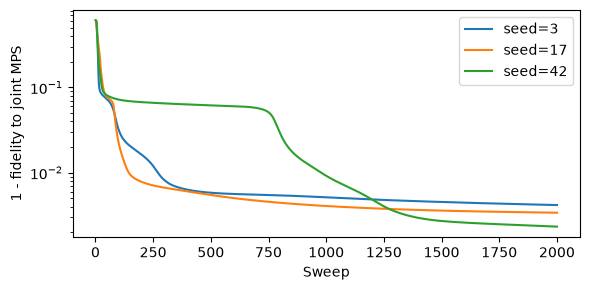

In [6]:
JOINT_TARGET = Statevector.from_instruction(A_APPROX).data
A_JOINT, JOINT_REPORT = compress_joint(
    JOINT_TARGET,
    layers=JOINT_LAYERS,
    sweeps=JOINT_SWEEPS,
    seeds=JOINT_SEEDS,
    chi=JOINT_CHI,
)
atomic_json(OUTPUT_DIR / "joint_compression.json", JOINT_REPORT)
with (OUTPUT_DIR / "joint_preparation.qpy").open("wb") as stream:
    qpy.dump(A_JOINT, stream)
print("Joint fidelity:", JOINT_REPORT["fidelity"])
print("Joint two-qubit blocks:", JOINT_REPORT["two_qubit_blocks"])
print("MPS retained norm squared:", JOINT_REPORT["mps_retained_norm_squared"])
print("Submission threshold:", MINIMUM_JOINT_FIDELITY)
fig, ax = plt.subplots(figsize=(6, 3))
for run in JOINT_REPORT["runs"]:
    ax.plot(
        np.arange(1, len(run["history"]) + 1),
        1 - np.array(run["history"]),
        label=f"seed={run['seed']}",
    )
ax.set(yscale="log", xlabel="Sweep", ylabel="1 - fidelity to joint MPS")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


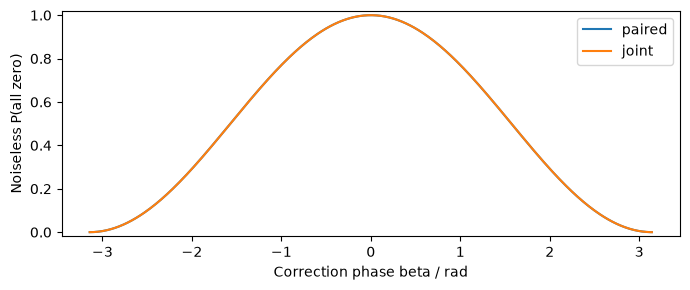

In [ ]:
from importlib.metadata import version


def current_configuration():
    return dict(
        geometry=SELECTED_GEOMETRY,
        baseline_digest=CIRCUIT_DIGEST,
        joint_digest=JOINT_REPORT["circuit_digest"],
        L=L,
        dt=DT,
        shots_per_phase=SHOTS_PER_PHASE,
        randomizations=RANDOMIZATIONS,
        phases=PHASES.tolist(),
        seed=SEED,
        run_label=RUN_LABEL,
        minimum_joint_fidelity=MINIMUM_JOINT_FIDELITY,
        layout_candidates=LAYOUT_CANDIDATES,
        max_active_qubits=MAX_ACTIVE_QUBITS,
        versions={
            name: version(name)
            for name in ["qiskit", "qiskit-ibm-runtime", "qiskit-aer"]
        },
    )


phase_grid = np.linspace(-np.pi, np.pi, 401)
fig, ax = plt.subplots(figsize=(7, 3))
for name, prep in [("paired", A_APPROX), ("joint", A_JOINT)]:
    ax.plot(phase_grid, ideal_signal(prep, L, phase_grid), label=name)
ax.set(
    xlabel="Correction phase beta / rad",
    ylabel="Noiseless P(all zero)",
    ylim=(-0.02, 1.02),
)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


## 4．集計と図

全ビットcountsを保持し、同じ位相の全0回数・実shots数を合計します。点ごとの95% Wilson区間と、
07と同じ一定確率に対する第一調和成分の条件付きMonte Carlo検査を表示します。3 armsでBonferroni補正します。
この検査は定常で独立な二項測定を仮定する診断です。randomized circuit間のばらつきやドリフトは別途確認してください。
arm間の有意／非有意の差だけで改善の有意差とは判断しません。振幅はノイズでも正になります。

左図は絶対確率0〜1、右図はcountsの範囲の拡大です。最大値で正規化せず、Gaussianを強制しません。
保存した理想曲線も結果JSONから読み出します。較正costは配置選択の指標であり、成功確率の予測ではありません。


In [ ]:
def show_comparison(record, title):
    scans = aggregate_comparison(record)
    spec = record["specification"]
    print("arm | all-zero / actual shots | amplitude | adjusted p")
    fig, axes = plt.subplots(3, 2, figsize=(11, 8))
    for row, scan in enumerate(scans):
        y = np.array(scan["observed"])
        low, high = np.array(scan["lower_95"]), np.array(scan["upper_95"])
        phase = np.array(scan["beta"])
        c, a, b = scan["coefficients"]
        dense = np.array(spec["ideal_phase_grid"])
        for column, ax in enumerate(axes[row]):
            ax.errorbar(
                phase,
                y,
                yerr=np.maximum(0, np.array([y - low, high - y])),
                fmt="o",
                capsize=2,
                ms=3,
                label="Counts / pointwise 95% CI",
            )
            ax.axhline(1 / 512, color="gray", ls=":", label="Uniform 9-bit reference")
            if column == 0:
                ax.plot(
                    dense,
                    spec["ideal_curves"][scan["arm"]],
                    "--",
                    label="This preparation, noiseless",
                )
                ax.set_ylim(-0.02, 1.02)
            else:
                curve = c + a * np.cos(dense) + b * np.sin(dense)
                ax.plot(dense, curve, label="Harmonic projection (descriptive)")
                ax.set_ylim(
                    min(0.0, float(curve.min()) * 1.1),
                    max(float(high.max()), float(curve.max()), 1 / 512) * 1.15,
                )
            ax.set(
                xlabel="Correction phase beta / rad",
                ylabel="P(all zero)",
                title=scan["arm"] + (" (zoom)" if column else ""),
            )
            ax.legend(fontsize=6)
        print(
            f"{scan['arm']} | {sum(scan['counts_all_zero'])}/{sum(scan['actual_shots'])} | "
            f"{scan['amplitude']:.6g} | {scan['p_adjusted']:.4g}"
        )
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    return scans


## 5．FakeKawasaki：ゲート・読出し・idleのノイズを含める

過去の127-qubit・ECRゲートのFakeKawasakiを使い、現在のCZ装置との差を結果へ記録します。
`refresh()` は呼びません。各armをALAPでscheduleし、suppressedにはXX-DDを明示的に挿入します。
全armでgate/readoutノイズに加え、明示的Delayに較正T1/T2の緩和を追加します。
**RuntimeのDD/twirlingオプションをfakeへ渡して「有効」とみなす方法は使いません。**

このfakeモデルには追加のcoherent idle driftやクロストークを入れません。
Markovianな緩和だけではDDやtwirlingの利益が見えない場合があり、追加パルスの誤りで悪化することもあります。
結果は改善を仮定せずに比較してください。未使用の物理qubitへのpaddingは除外します。
各実行回路の理想確率を検証（許容差1e-7）してから、ノイズ付き測定へ進みます。

初回は回路生成と72回路の密度行列シミュレーションで時間がかかります。`RUN_FAKE=False` でスキップできます。


{"arm": "paired", "depth": 2613, "two_qubit_gates": 1260, "x_gates": 178, "delay_instructions": 19, "active_physical_qubits": [109, 114, 115, 116, 117, 118, 119, 120, 121], "initial_layout": [120, 119, 118, 117, 116, 115, 114, 109, 121], "calibration_cost": 11.130837275506542, "missing_calibration_entries": 0, "ideal_probability_max_error": 1.3455903058456897e-13}
{"arm": "joint", "depth": 638, "two_qubit_gates": 406, "x_gates": 30, "delay_instructions": 10, "active_physical_qubits": [109, 114, 115, 116, 117, 118, 119, 120, 121], "initial_layout": [120, 119, 118, 117, 116, 115, 114, 109, 121], "calibration_cost": 3.9650672696335, "missing_calibration_entries": 0, "ideal_probability_max_error": 4.080846771614688e-12}
{"arm": "suppressed", "depth": 781, "two_qubit_gates": 369, "x_gates": 782, "delay_instructions": 39, "active_physical_qubits": [54, 62, 63, 64, 72, 78, 79, 80, 81], "initial_layout": [79, 80, 81, 72, 62, 63, 64, 54, 78], "calibration_cost": 3.2227679250872088, "missing_cal

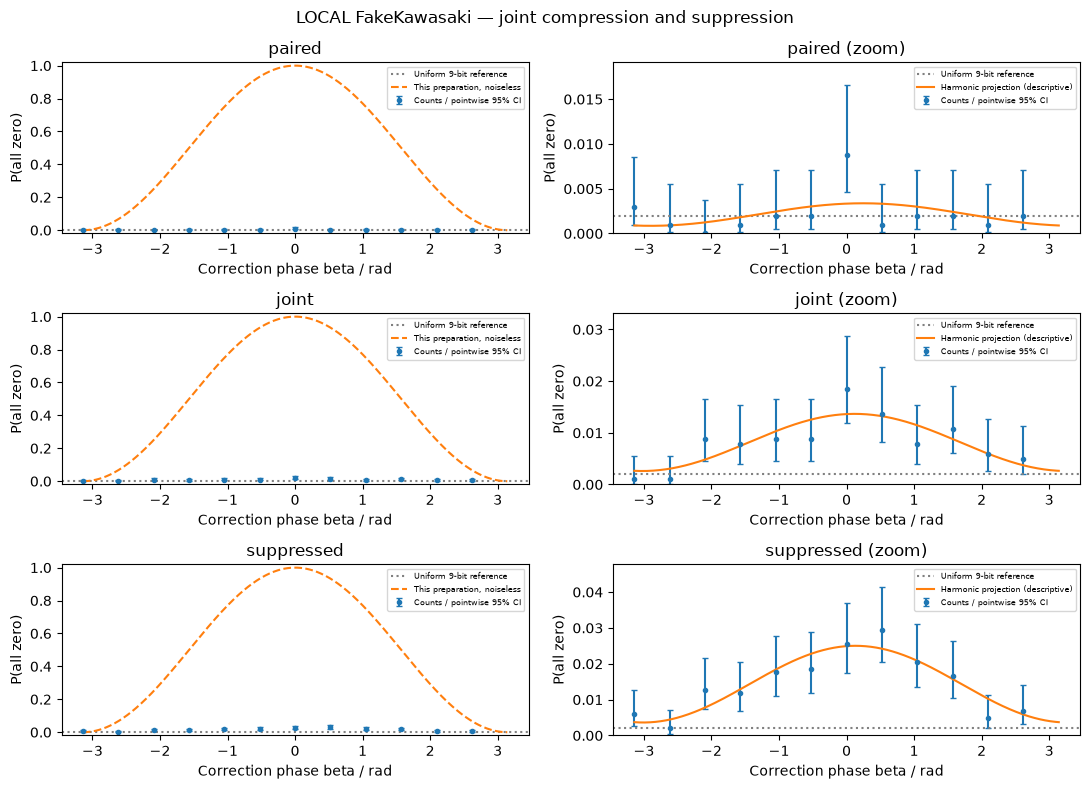

In [9]:
fake_record = None
fake_preview = None
if RUN_FAKE:
    from qiskit_ibm_runtime.fake_provider import FakeKawasaki

    fake_backend = FakeKawasaki()
    fake_preview = compile_comparison(
        fake_backend, A_JOINT, JOINT_REPORT, current_configuration()
    )
    with (OUTPUT_DIR / "fake_submitted_circuits.qpy").open("wb") as stream:
        qpy.dump(fake_preview["circuits"], stream)
    fake_record = run_fake_comparison(fake_preview, fake_backend)
    fake_path = OUTPUT_DIR / "fake_measurements.json"
    atomic_json(fake_path, fake_record)
    print("Saved raw fake counts:", fake_path)
    fake_summary = show_comparison(
        fake_record, "LOCAL FakeKawasaki — joint compression and suppression"
    )
    atomic_json(
        OUTPUT_DIR / "fake_analysis.json",
        dict(
            source="fake_analysis",
            specification=fake_record["specification"],
            scans=fake_summary,
        ),
    )
else:
    print("Fake simulation skipped.")


## 6．実機接続（任意、ここでは送信しない）

`USE_IBM=True` にしてCRN・本人のAPIキー・backendを入力します。APIキーは非表示入力です。
較正・ターゲット・配置は実機から読み直します。FakeKawasakiの配置や較正は実機に流用しません。
通常のCZ/ECR/CXゲートを使うため、fractional gatesを無効にしてbackendを取得します。


In [ ]:
USE_IBM = False
IBM_SERVICE = None
IBM_INSTANCE = ""
real_backend = None
real_preview = None
if USE_IBM:
    from getpass import getpass
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input("今回使うインスタンスのCRN：").strip()
    if not IBM_INSTANCE.startswith("crn:"):
        raise ValueError("crn:で始まるインスタンスCRNを指定してください")
    token = getpass("本人のAPIキー（非表示）：").strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel="ibm_quantum_platform", token=token, instance=IBM_INSTANCE
        )
    finally:
        del token
    names = sorted(b.name for b in IBM_SERVICE.backends())
    print("利用可能なbackend:", ", ".join(names))
    name = input("今回使うbackend名：").strip()
    if name not in names:
        raise ValueError("一覧からbackend名を指定してください")
    real_backend = IBM_SERVICE.backend(name, use_fractional_gates=False)
    print("Connected:", real_backend.name, "— no job submitted")
else:
    print("IBM connection skipped.")


IBM connection skipped.


## 7．実機の費用をプレビューし、その回路を保存する

全armの深さ・native 2-qubitゲート数・追加X・Delay・使用qubit・較正cost・理想確率の最大誤差を確認してください。
baselineとjointは同じ初期配置、suppressedは新しく較正から選んだ配置です。
DDとtwirlingはすでに回路へ入っています。送信時には再トランスパイルせず、追加のRuntime抑制も無効にします。
各armの費用表は代表の1回路です。全位相・randomizationの正確な回路はQPYに保存します。


In [ ]:
if real_backend is not None:
    real_preview = compile_comparison(
        real_backend, A_JOINT, JOINT_REPORT, current_configuration()
    )
    atomic_json(OUTPUT_DIR / "real_preview.json", real_preview["specification"])
else:
    print("Real-backend preview skipped.")


Real-backend preview skipped.


## 8．実機測定（費用確認後に有効化）

`RUN_HARDWARE=True` で、プレビュー済みの全armを1ジョブへ送信します。
正確なISA回路、送信マーカー、ジョブIDを保存し、取得した全countsを解析前に保存します。
同じ条件・較正・回路・instance・RUN_LABELでは保存結果またはジョブを再利用します。
IDのない送信マーカーが残った場合は、IBMのジョブ一覧を確認して復旧してください。自動再送信しません。
Colab切断前には `outputs/exercise8/` をDrive等に保存してください。


In [ ]:
RUN_HARDWARE = False
real_record = None
real_path = None
if RUN_HARDWARE:
    real_record, real_path = acquire_real_comparison(
        real_preview,
        IBM_SERVICE,
        real_backend,
        IBM_INSTANCE,
        OUTPUT_DIR / "ibm_jobs",
        current_configuration(),
    )
    print("Saved raw real-device counts:", real_path)
else:
    print("No QPU submission. Connect → preview → enable RUN_HARDWARE to run.")


No QPU submission. Connect → preview → enable RUN_HARDWARE to run.


## 9．実機結果、または保存JSONの再解析

`RESULT_FILE` が未指定なら上の実機結果を使います。指定した場合は、その保存JSONに含まれるcounts・
条件・理想曲線で解析するため、再接続や同じ準備回路の再最適化は不要です。
（この節と集計用の関数だけを実行する場合は、numpy・matplotlib等のimportが必要です。）


In [ ]:
RESULT_FILE = (
    None  # 例: 'outputs/exercise8/ibm_jobs/<key>.json' または保存fake_measurements.json
)
analysis_record = (
    json.loads(Path(RESULT_FILE).read_text()) if RESULT_FILE else real_record
)
analysis_path = Path(RESULT_FILE) if RESULT_FILE else real_path
if analysis_record is not None:
    title = (
        "IBM hardware"
        if analysis_record["source"] == "ibm_raw_counts"
        else "Saved fake simulation"
    )
    scans = show_comparison(
        analysis_record, title + " — joint compression and suppression"
    )
    summary_path = analysis_path.with_suffix(".analysis.json")
    atomic_json(
        summary_path,
        dict(
            source="comparison_analysis",
            job_id=analysis_record.get("job_id"),
            specification=analysis_record["specification"],
            scans=scans,
        ),
    )
    print("Saved analysis:", summary_path)
else:
    print(
        "No real-device counts. The fake comparison above is independent of IBM access."
    )


No real-device counts. The fake comparison above is independent of IBM access.


## 10．何が分かるか

- paired→jointでnativeゲート数や信号が改善すれば、準備回路の実装コストが重要だった証拠になります。
  jointの理想信号も同時に確認し、回路圧縮の近似による差を混同しません。
- suppressedは複数の変更を束ねています。改善／悪化した原因を分けるには、配置・level・DD・twirlingを個別に変えた追加実験が必要です。
- L=1で回復したら、`L=4` にして06と同じ発展時間で確認できます。Lを変えるときは設定以降を再実行してください。
- 全armが平坦なら、それも結果です。fakeでの成功を実機の保証とせず、shots増加だけで回復するとは判断しません。
- 読出し誤りの緩和は行っていません。生countsのまま比較します。FireOpalによるパルス最適化や独自の抑制も含みません。

参考：[Kanno et al., PNAS (2025), SI S2](https://doi.org/10.1073/pnas.2425026122)、
[Qiskitの誤り抑制](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques)、
[SamplerOptions v0.43](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/0.43/options-sampler-options)。
